# Basic workflow
## Obtain Data from API
Paste your token in the token variable

In [1]:
import requests
import pandas as pd
import math 


In [2]:

api_url='https://xray-api.renecol.org'
token='DLkevyX247TBgr5Jl7fvGRSO03k3YG'
image_suffix='/api/imagedata/'
response = requests.get(headers={'Authorization': 'Bearer ' + token},url=api_url+image_suffix, params={'detailed':True, 'complete':True}).json()
df = pd.DataFrame(response)
df2 = df[['id','patient_id','measure_dataset','referring_patient','img_type','acquisition_date']]
# filter those rows where measure_dataset is not an empty list
df3 = df2[df2['measure_dataset'].map(lambda d: len(d)) > 0]

# unpack measure_dataset column and combine it with the rest of df3, renaming the columns appropriately 
df4 = pd.concat([df3.drop(columns=['measure_dataset']), df3['measure_dataset'].apply(pd.Series)], axis=1)
# transfer to long format
df4b=df4.melt(id_vars=['id','patient_id','referring_patient','img_type','acquisition_date'], value_name='measure_dataset', var_name='measure_dataset_index').dropna(subset=['measure_dataset'])
df4c = pd.concat([df4b.drop(columns=['measure_dataset']), df4b['measure_dataset'].apply(pd.Series)['data']], axis=1)
df4d = pd.concat([df4c.drop(columns=['data']), df4c['data'].apply(pd.Series)], axis=1)
df4d

,id,patient_id,referring_patient,img_type,acquisition_date,measure_dataset_index,xray_measurement_data
0,800,BKII,"{'id': 109, 'hasClinicalBaseData': 1, 'complet...",MRI-LWS-cor,2021-01-29,0,"{'angles': [{'cobbType': 'Spline', 'cobbAngle'..."
1,799,BKII,"{'id': 109, 'hasClinicalBaseData': 1, 'complet...",Xray-LWS-lat,2019-08-05,0,"{'angles': [{'cobbType': 'Spline', 'cobbAngle'..."
2,798,BKII,"{'id': 109, 'hasClinicalBaseData': 1, 'complet...",Xray-LWS-ap,2019-08-05,0,"{'angles': [{'cobbType': 'Spline', 'cobbAngle'..."
3,797,EEGE,"{'id': 108, 'hasClinicalBaseData': 1, 'complet...",Xray-LWS-lat,2024-04-30,0,"{'angles': [{'cobbType': 'Spline', 'cobbAngle'..."
4,796,EEGE,"{'id': 108, 'hasClinicalBaseData': 1, 'complet...",Xray-LWS-ap,2024-04-30,0,"{'angles': [{'cobbType': 'Spline', 'cobbAngle'..."
...,...,...,...,...,...,...,...
1413,100,RZR4,"{'id': 7, 'hasClinicalBaseData': 1, 'completeN...",Xray-LWS-ap,2025-05-04,2,"{'angles': [{'cobbType': 'Spline', 'cobbAngle'..."
1424,83,SX4G,"{'id': 6, 'hasClinicalBaseData': 0, 'completeN...",Xray-LWS-lat,2020-07-07,2,"{'angles': [{'cobbType': 'Spline', 'cobbAngle'..."
1430,55,JXJ9,"{'id': 2, 'hasClinicalBaseData': 0, 'completeN...",MRI-LWS-cor,2020-02-19,2,"{'angles': [{'cobbType': 'Spline', 'cobbAngle'..."
1769,263,RCI6,"{'id': 35, 'hasClinicalBaseData': 0, 'complete...",Xray-LWS-ap,2016-02-09,3,"{'angles': [{'cobbType': 'Spline', 'cobbAngle'..."


In [41]:
df4d.to_pickle('data/df4d_spine_measurements.pkl')

In [4]:
# create df5c
df5 = pd.concat([df4d.drop(columns=['xray_measurement_data']), df4d['xray_measurement_data'].apply(pd.Series)], axis=1)
# use df5 for subsequent analysis

df5a = df5.drop(columns=['calibration', 'stateObject','globalParams'])
df5b = pd.concat([df5a.drop(columns=['angles']), df5a['angles'].apply(pd.Series)], axis=1)
df5c=df5b.melt(id_vars=['id','patient_id','referring_patient','acquisition_date','img_type','measure_dataset_index'], value_name='angle_data', var_name='angle_index').dropna(subset=['angle_data'])

# Analyzing angles differences data
This section describes the statistical analysis of angles measured by the algorithms inside the xray-annotator app.

In [9]:
# if reading from pickle data, that way one can include reconstructed cobb angles
df5c = pd.read_pickle('data/df5c_with_reconstructed_angles.pkl')
df5c_corrected = pd.read_pickle('data/df5c_corrected_with_reconstructed_angles.pkl')

In [7]:
def transform_df5c(df5c):
    df6 = pd.concat([df5c.drop(columns=['angle_data']), df5c['angle_data'].apply(pd.Series)], axis=1)
    df6b=pd.concat([df6.drop(columns=['cobbAngle','lineColor','lowerLine','upperLine']), df6['cobbAngle'].apply(pd.Series)], axis=1)
    # drop all rows where vertebra_lower or vertebra_upper == '?'
    df6c = df6b[(df6b['vertebra_lower'] != '?') & (df6b['vertebra_upper'] != '?')]
    
    spine_labels = ['C0','C1','C2','C3','C4','C5','C6','C7','T1','T2','T3','T4','T5','T6','T7','T8','T9','T10','T11','T12','L1','L2','L3','L4','L5','S1']
    spine_regions = {'CT':[0,9],'PT': [10,12],'MT':[13,18],'TL':[19,20],'LU':[21,25]}
    
    # function to map the mean of the indices of vertebra_lower and vertebra_upper to a spine region
    def map_to_spine_region(row):
        if row['cobbType']=='Cobb-segmental':
            return row['vertebra_upper']
        lower_index = spine_labels.index(row['vertebra_lower'])
        upper_index = spine_labels.index(row['vertebra_upper'])
        mean_index = math.ceil((lower_index + upper_index) / 2)
        for region, (start, end) in spine_regions.items():
            if start <= mean_index <= end:
                return region
        print(mean_index)
        return 'Unknown'   
    
    df6c.loc[:,'spine_region']=df6c.apply(map_to_spine_region, axis=1)
    return df6c
    
df6c=transform_df5c(df5c)
#df6c_corrected=transform_df5c(df5c_corrected)

/var/folders/0p/dhp7vkq101162y0s0v9s4gz80000gn/T/ipykernel_99737/3064844995.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df6c.loc[:,'spine_region']=df6c.apply(map_to_spine_region, axis=1)


# Standard deviation of angles by spine region
## xray-annotator values

In [15]:
def transform_df6c(df6c):
    df6d=df6c.groupby(['id','cobbType','img_type','spine_region']).agg({'angle':['mean','count','std']}).reset_index()
    df6d.dropna(inplace=True)
    df6e=df6d.drop(columns=[('angle','count'),('angle','mean')])
    # reset the multiindex columns
    df6e.columns = ['_'.join(col).strip() if col[1] else col[0] for col in df6e.columns.values]
    mask=((df6e['cobbType']!='Cobb-segmental') & (df6e['cobbType']!='reconstructed_segmental') & 
          ((df6e['img_type']=='Xray-LWS-ap') | (df6e['img_type']=='Xray-LWS-lat')))
    df6f = df6e.loc[mask,:]
    return df6d,df6f

df6d,df6f=transform_df6c(df6c)
df6d_corrected,df6f_corrected=transform_df6c(df6c_corrected)

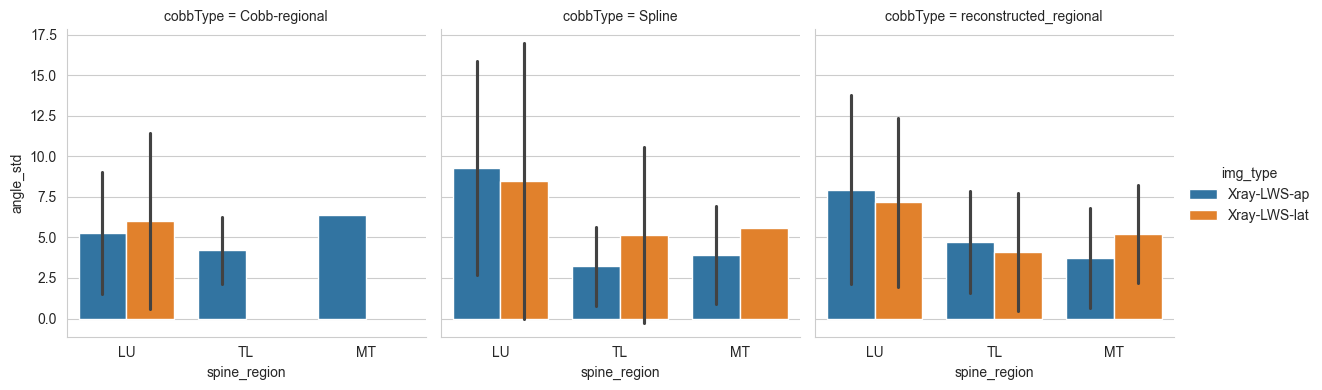

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
cobbTypeOrder = ['Cobb-regional','Spline','reconstructed_regional']
g=sns.catplot(data=df6f, x='spine_region', y='angle_std', hue='img_type', col='cobbType', col_order=cobbTypeOrder, kind='bar', height=4, aspect=1, errorbar='sd')
g.fig.savefig('output/angle_std_by_spine_region.png')


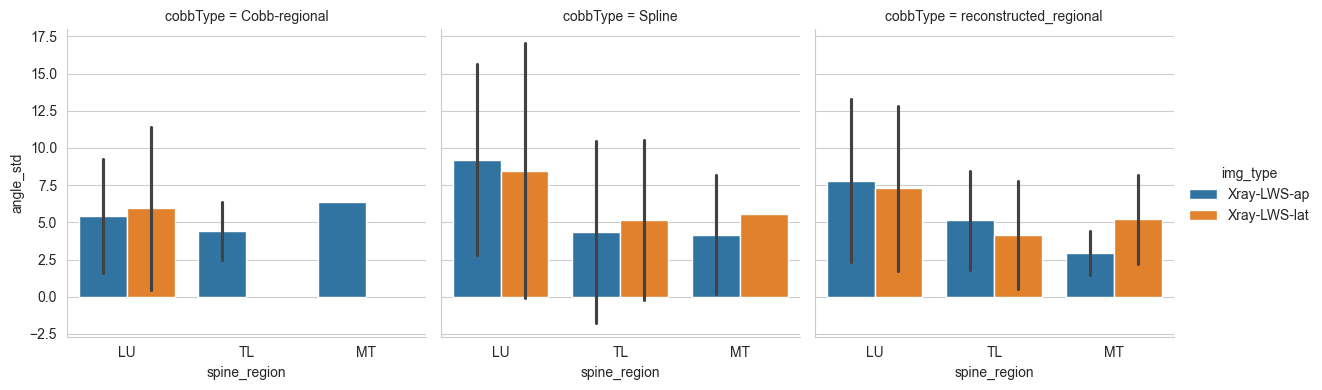

In [14]:
g=sns.catplot(data=df6f_corrected, x='spine_region', y='angle_std', hue='img_type', col='cobbType', col_order=cobbTypeOrder, kind='bar', height=4, aspect=1, errorbar='sd')
g.fig.savefig('output/angle_std_by_spine_region_corrected.png')

So as for now, it has to be stated, that re-labelling the whole dataset did not change std of the angles.

In [26]:
newCols=['id','cobbType','img_type','spine_region','angle_mean','angle_count','angle_std']
# reset the multiindex of df6d columns
df6d.columns = ['_'.join(col).strip() if col[1] else col[0] for col in df6d.columns.values]
df6g=df6d[newCols]
df6g.to_pickle('data/df6g_angle_stats_by_spine_region.pkl')
df6g.loc[:20,:].to_json('data/df6g_angle_stats_by_spine_region_sample.json',orient='records')
df6g.to_json('data/df6g_angle_stats_by_spine_region.json',orient='records')

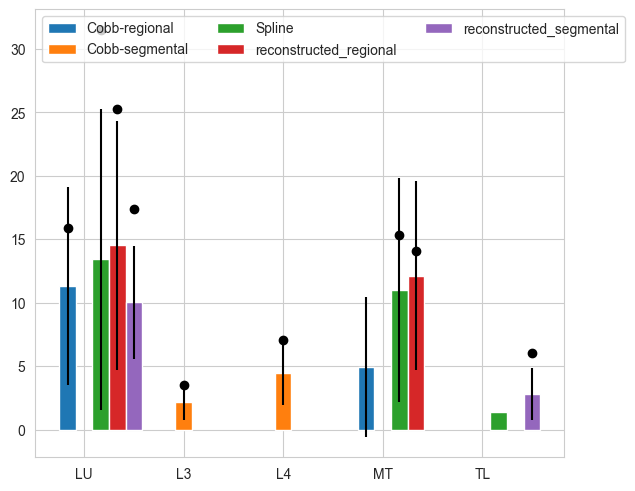

In [39]:
import numpy as np
current_id=488

df_current = df6g.loc[df6g['id']==current_id]
current_img_type = df_current['img_type'].values[0]
possible_cobbTypes = list(df_current['cobbType'].unique())
possible_spine_regions = list(df_current['spine_region'].unique())

x = np.arange(len(possible_spine_regions))  # the label locations
width = 1/(len(possible_cobbTypes)+1)  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

cobbStds = {}
cobbErrors = {}
activeVals = {}
for cobbType in possible_cobbTypes:
    stds = []
    errs = []
    vals=[]
    for region in possible_spine_regions:
        s = df6g.loc[(df6g['img_type']==current_img_type) & (df6g['cobbType']==cobbType) & (df6g['spine_region']==region),'angle_std'].mean()
        stds.append(s)
        e = df6g.loc[(df6g['img_type']==current_img_type) & (df6g['cobbType']==cobbType) & (df6g['spine_region']==region),'angle_std'].std()
        errs.append(e)
        t = df_current.loc[(df_current['cobbType']==cobbType) & (df_current['spine_region']==region),'angle_std'].mean()
        vals.append(t)
    activeVals[cobbType] = vals
    cobbStds[cobbType] = stds
    cobbErrors[cobbType] = errs

for (attribute, measurement), (_,error),(_, current_measurement) in zip(cobbStds.items(), cobbErrors.items(), activeVals.items()):
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width,yerr=error, label=attribute)
    ax.errorbar(x+offset, current_measurement,  fmt='o', color='black', capsize=5)
    # ax.bar_label(rects, padding=3)
    multiplier += 1
    
ax.set_xticks(x + width, possible_spine_regions)
ax.legend(loc='upper left', ncols=3)

plt.show()

# Longitudinal axis
Get the time dependent change in angles

In [74]:
df6c['acquisition_date']=df6c['acquisition_date'].apply(pd.to_datetime)

/var/folders/v5/10wd6_3x1xz6vdd_jj69w80r0000gn/T/ipykernel_4631/3699863829.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df6c['acquisition_date']=df6c['acquisition_date'].apply(pd.to_datetime)


In [75]:
df7=df6c.sort_values(['acquisition_date'], ascending=True)

In [100]:
df7a=df7.groupby(['patient_id','img_type','spine_region','acquisition_date','cobbType']).agg({'angle':['mean','std','count']})

## Specific patient

In [101]:
patient_id='SX4G'
img_type='Xray-LWS-lat'
region='LU'

# from grouped df
df7a.loc[patient_id,img_type,region]

angle                 
                                mean        std count
acquisition_date cobbType                            
2020-05-04       Cobb-regional  55.0        NaN     1
                 Spline         63.0        NaN     1
2020-07-17       Cobb-regional  73.5  16.263456     2
                 Spline         83.5   2.121320     2
2020-11-06       Spline         42.0        NaN     1
2020-11-19       Cobb-regional  47.0        NaN     1
                 Spline         39.0        NaN     1

In [96]:
# through raw values
df7_p=df7.loc[(df7.patient_id==patient_id) & (df7.img_type==img_type) & (df7.spine_region==region),['acquisition_date','angle']]

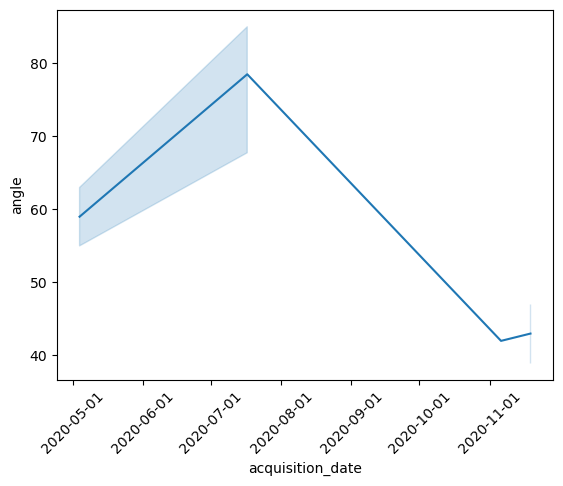

In [97]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
sns.lineplot(df7_p,x='acquisition_date',y='angle')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.xticks(rotation=45)
plt.show()